In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

print("Environment ready!")

Matplotlib is building the font cache; this may take a moment.


Environment ready!


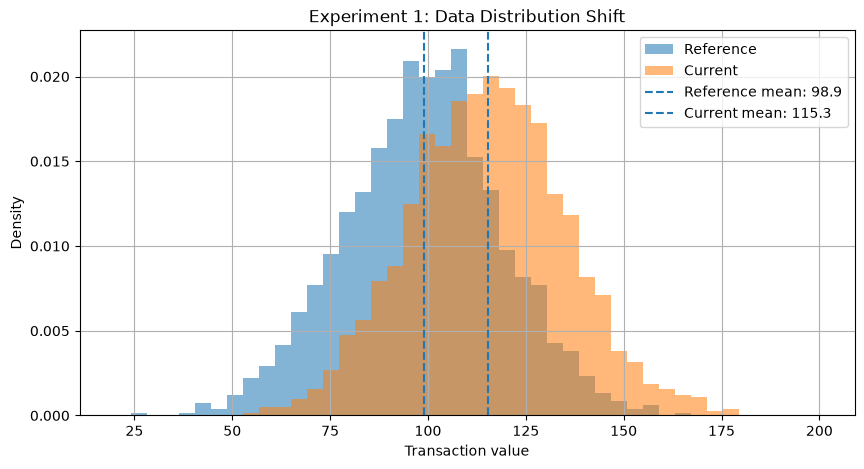

Reference mean: 98.90
Current mean: 115.32


In [2]:

# Simulate transaction values before and after a shift
n = 2000

reference = rng.normal(loc=100, scale=20, size=n)
current = rng.normal(loc=115, scale=20, size=n)

# Visualize both distributions
bins = np.linspace(20, 200, 45)

plt.hist(reference, bins=bins, alpha=0.55,
         density=True, label="Reference")
plt.hist(current, bins=bins, alpha=0.55,
         density=True, label="Current")

plt.axvline(reference.mean(), linestyle="--",
            label=f"Reference mean: {reference.mean():.1f}")
plt.axvline(current.mean(), linestyle="--",
            label=f"Current mean: {current.mean():.1f}")

plt.xlabel("Transaction value")
plt.ylabel("Density")
plt.title("Experiment 1: Data Distribution Shift")
plt.legend()
plt.show()

print(f"Reference mean: {reference.mean():.2f}")
print(f"Current mean: {current.mean():.2f}")


In [3]:

ks_stat, p_value = ks_2samp(reference, current)

print(f"KS Statistic: {ks_stat:.4f}")
print(f"P-value: {p_value:.6g}")

alpha = 0.05

if p_value < alpha:
    print("Statistically significant distribution difference detected.")
else:
    print("No statistically significant difference detected.")

# Compare with a sample showing no intentional shift
stable = rng.normal(loc=100, scale=20, size=n)

stable_ks, stable_p = ks_2samp(reference, stable)

print("\nNo-shift comparison:")
print(f"KS Statistic: {stable_ks:.4f}")
print(f"P-value: {stable_p:.6g}")


KS Statistic: 0.3300
P-value: 8.7189e-97
Statistically significant distribution difference detected.

No-shift comparison:
KS Statistic: 0.0350
P-value: 0.172496


In [4]:

# Generate the original data
rng = np.random.default_rng(123)

n = 5000
X = rng.normal(0, 1, size=(n, 1))

# Higher feature values indicate higher risk
probability = 1 / (1 + np.exp(-3 * X[:, 0]))
y = rng.binomial(1, probability)

# Train on the first 70%, evaluate on remaining 30%
split = int(0.7 * n)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

baseline_pred = model.predict(X_test)
baseline_prob = model.predict_proba(X_test)[:, 1]

print("Original model performance:")
print(f"Accuracy: {accuracy_score(y_test, baseline_pred):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, baseline_prob):.3f}")


Original model performance:
Accuracy: 0.843
ROC-AUC: 0.925


In [5]:

# Incoming production data
X_new = rng.normal(0, 1, size=(2000, 1))

# New relationship: larger X now means lower risk
new_probability = 1 / (1 + np.exp(3 * X_new[:, 0]))
y_new = rng.binomial(1, new_probability)

# Evaluate the original model on incoming data
new_pred = model.predict(X_new)
new_prob = model.predict_proba(X_new)[:, 1]

# Check for input feature drift
ks_stat, ks_p = ks_2samp(X_train[:, 0], X_new[:, 0])

results = pd.DataFrame({
    "Metric": ["Accuracy", "ROC-AUC"],
    "Before Drift": [
        accuracy_score(y_test, baseline_pred),
        roc_auc_score(y_test, baseline_prob)
    ],
    "After Drift": [
        accuracy_score(y_new, new_pred),
        roc_auc_score(y_new, new_prob)
    ]
})

print("Feature distribution KS p-value:", round(ks_p, 4))
print("\nModel performance comparison:")
print(results.round(3).to_string(index=False))


Feature distribution KS p-value: 0.0278

Model performance comparison:
  Metric  Before Drift  After Drift
Accuracy         0.843        0.176
 ROC-AUC         0.925        0.088


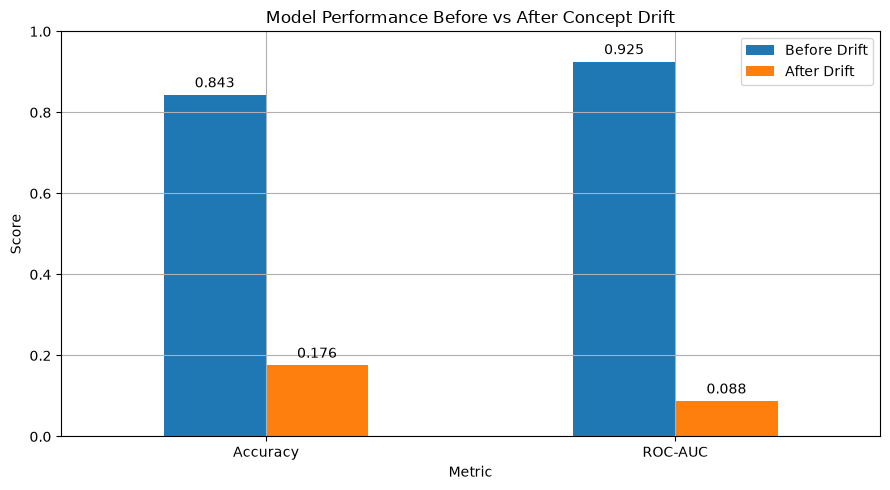

In [6]:

ax = results.set_index("Metric").plot(
    kind="bar",
    rot=0,
    ylim=(0, 1),
    figsize=(9, 5),
    title="Model Performance Before vs After Concept Drift"
)

ax.set_ylabel("Score")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()
